# JS11 Assignment - CNN Classification

Two tasks:

1. Modify the CNN model from **Practical Session 2** (`JS11-02`, the CIFAR-10 CNN)
   so that the **Cats vs Dogs** binary classifier reaches a **test accuracy above 80%**.
2. Build a CNN to classify the **MNIST** handwritten-digit dataset.


---
## Part 1 - Cats vs Dogs CNN (test accuracy > 80%)


### Part 1 / Step 1 - Load Libraries

In [1]:
import tensorflow as tf

from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

### Part 1 / Step 2 - Load the Cats vs Dogs Dataset

The images are read straight from disk with `image_dataset_from_directory`.
They are resized to `64x64` and labelled binarily (`cats = 0`, `dogs = 1`),
matching the setup used in `JS11-01`.

In [2]:
IMG_SIZE = (64, 64)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    'dataset/training_set',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary',
    shuffle=True,
    seed=1,
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    'dataset/test_set',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary',
    shuffle=False,
)

print('Class names:', train_ds.class_names)
print('Class indices: {\'cats\': 0, \'dogs\': 1}')
print('Train batches:', tf.data.experimental.cardinality(train_ds).numpy())
print('Test  batches:', tf.data.experimental.cardinality(test_ds).numpy())

Found 8000 files belonging to 2 classes.
Found 2000 files belonging to 2 classes.
Class names: ['cats', 'dogs']
Class indices: {'cats': 0, 'dogs': 1}
Train batches: 250
Test  batches: 63


### Part 1 / Step 3 - Data Augmentation

The images are rescaled to `[0, 1]` and then augmented (flip, zoom, rotation)
to reduce overfitting. Augmentation is applied only to the training set through
`.map(...)`, so the test set stays untouched.

In [3]:
data_augmentation = tf.keras.Sequential([
    layers.Rescaling(1./255),
    layers.RandomFlip('horizontal'),
    layers.RandomZoom(0.2),
    layers.RandomRotation(0.1),
], name='data_augmentation')

AUTOTUNE = tf.data.AUTOTUNE

train_set = train_ds.map(
    lambda x, y: (data_augmentation(x, training=True), y),
    num_parallel_calls=AUTOTUNE,
).prefetch(AUTOTUNE)

test_set = test_ds.map(
    lambda x, y: (layers.Rescaling(1./255)(x), y),
    num_parallel_calls=AUTOTUNE,
).prefetch(AUTOTUNE)

### Part 1 / Step 4 - Construct the CNN Model

This keeps the same convolutional shape as `JS11-02` (three `Conv2D` blocks:
32 -> 64 -> 64, each followed by `MaxPooling2D`), but adds `BatchNormalization`
for stable training and `Dropout` to fight overfitting. The head is adapted to
the binary task: a single `Dense(1, sigmoid)` output instead of `Dense(10)`.

In [4]:
model = models.Sequential([
    layers.Input(shape=(64, 64, 3)),

    # Block 1
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Fully connected head
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid'),
])

### Part 1 / Step 5 - Inspect the Model Architecture

In [5]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 319,233 (1.22 MB)

 Trainable params: 318,913 (1.22 MB)

 Non-trainable params: 320 (1.25 KB)

### Part 1 / Step 6 - Compile the Model

Binary classification uses `binary_crossentropy` and a `sigmoid` output.

In [6]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy'],
)

### Part 1 / Step 7 - Fit the Model

`EarlyStopping` halts training once `val_loss` stops improving and restores the
best weights, while `ReduceLROnPlateau` lowers the learning rate when progress
stalls. Together they let the model reach (and keep) its best accuracy.

In [7]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6
    ),
]

history = model.fit(
    train_set,
    validation_data=test_set,
    epochs=30,
    callbacks=callbacks,
)

Epoch 1/30


C:\Users\andhi\AppData\Roaming\Python\Python314\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


250/250 ━━━━━━━━━━━━━━━━━━━━ 15s 54ms/step - accuracy: 0.5916 - loss: 0.6915 - val_accuracy: 0.6475 - val_loss: 0.6430 - learning_rate: 0.0010
Epoch 2/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 15s 58ms/step - accuracy: 0.6604 - loss: 0.6170 - val_accuracy: 0.6490 - val_loss: 0.6728 - learning_rate: 0.0010
Epoch 3/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 14s 56ms/step - accuracy: 0.6836 - loss: 0.5946 - val_accuracy: 0.6440 - val_loss: 0.6539 - learning_rate: 0.0010
Epoch 4/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 14s 54ms/step - accuracy: 0.7023 - loss: 0.5667 - val_accuracy: 0.7115 - val_loss: 0.5529 - learning_rate: 0.0010
Epoch 5/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 13s 52ms/step - accuracy: 0.7240 - loss: 0.5462 - val_accuracy: 0.6835 - val_loss: 0.5660 - learning_rate: 0.0010
Epoch 6/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 13s 52ms/step - accuracy: 0.7430 - loss: 0.5268 - val_accuracy: 0.7590 - val_loss: 0.4922 - learning_rate: 0.0010
Epoch 7/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 13s 51ms/step - accuracy: 0.7530 - loss: 0.5105

### Part 1 / Step 8 - Evaluate the Model

Plot training vs validation accuracy, then evaluate on the test set.

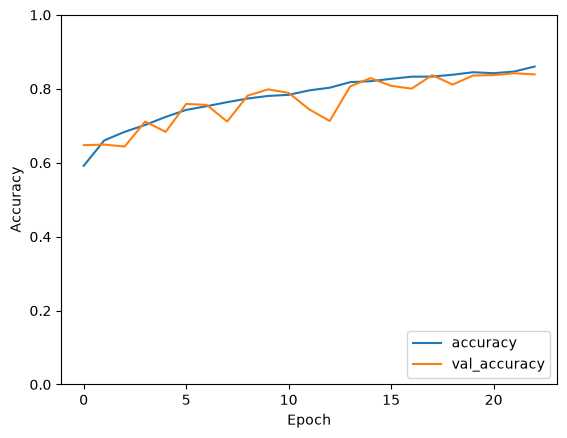

63/63 - 1s - 11ms/step - accuracy: 0.8370 - loss: 0.3690
Test accuracy: 0.8370000123977661


In [8]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')
plt.show()

test_loss, test_acc = model.evaluate(test_set, verbose=2)
print('Test accuracy:', test_acc)

### Part 1 / Step 9 - Print the Result

Did the modified model clear the required **80%** test accuracy?

In [9]:
print(f'Test accuracy: {test_acc:.4f}')

if test_acc > 0.80:
    print('SUCCESS: test accuracy exceeds 80%.')
else:
    print('BELOW TARGET: test accuracy does not exceed 80%.')

Test accuracy: 0.8370
SUCCESS: test accuracy exceeds 80%.


---
## Part 2 - MNIST CNN

A CNN to classify the 10 handwritten-digit classes of MNIST.

### Part 2 / Step 1 - Load Libraries

In [10]:
import tensorflow as tf

from tensorflow.keras import datasets, layers, models
import numpy as np
import matplotlib.pyplot as plt

### Part 2 / Step 2 - Download the MNIST Dataset

The images are `28x28` greyscale; a channel axis is added and pixel values are
normalised to `[0, 1]`.

In [11]:
(train_images, train_labels), (test_images, test_labels) = datasets.mnist.load_data()

# Reshape from (N, 28, 28) to (N, 28, 28, 1) to add the channel dimension.
train_images = train_images.reshape(-1, 28, 28, 1) / 255.0
test_images = test_images.reshape(-1, 28, 28, 1) / 255.0

print('Train shape:', train_images.shape)
print('Test  shape:', test_images.shape)

Train shape: (60000, 28, 28, 1)
Test  shape: (10000, 28, 28, 1)


### Part 2 / Step 3 - Verify the Data

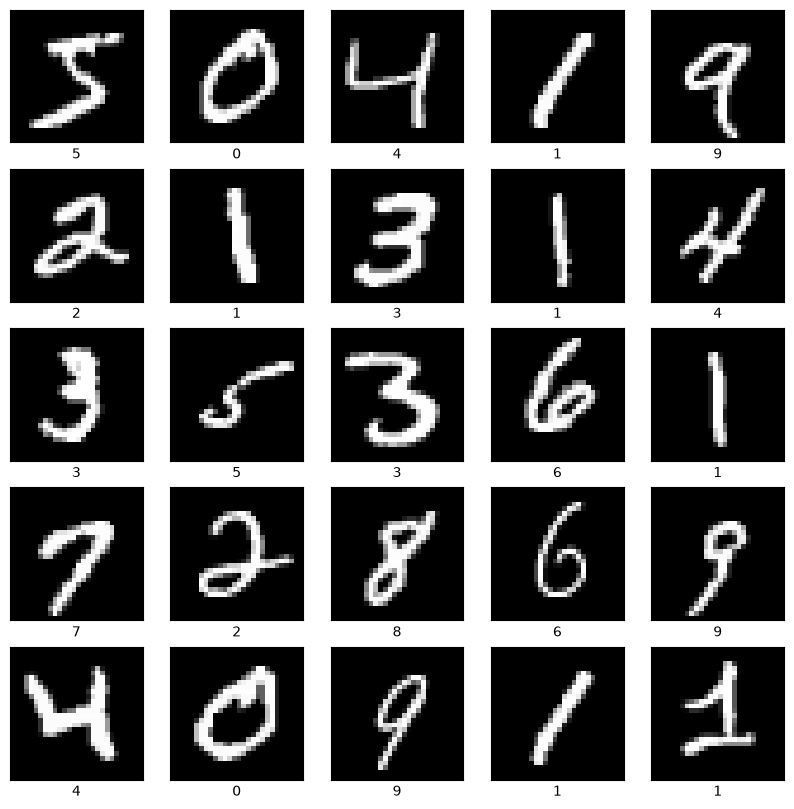

In [12]:
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i].reshape(28, 28), cmap='gray')
    plt.xlabel(train_labels[i])
plt.show()

### Part 2 / Step 4 - Construct the CNN Model

The same convolutional pattern as `JS11-02`: two `Conv2D` blocks (32 -> 64)
with `MaxPooling2D`, then fully connected layers. The output is `Dense(10)`
**without** an activation because the loss uses `from_logits=True`.

In [13]:
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10),
])

### Part 2 / Step 5 - Inspect the Model Architecture

In [14]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

### Part 2 / Step 6 - Compile the Model

`SparseCategoricalCrossentropy(from_logits=True)` matches the logits output of
the final `Dense(10)` layer, exactly as in `JS11-02`.

In [15]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy'],
)

### Part 2 / Step 7 - Fit the Model

In [16]:
history = model.fit(
    train_images,
    train_labels,
    epochs=10,
    validation_data=(test_images, test_labels),
)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9039 - loss: 0.3113 - val_accuracy: 0.9808 - val_loss: 0.0613
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9635 - loss: 0.1231 - val_accuracy: 0.9869 - val_loss: 0.0413
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9720 - loss: 0.0934 - val_accuracy: 0.9888 - val_loss: 0.0376
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9770 - loss: 0.0757 - val_accuracy: 0.9878 - val_loss: 0.0367
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9792 - loss: 0.0686 - val_accuracy: 0.9910 - val_loss: 0.0306
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9817 - loss: 0.0592 - val_accuracy: 0.9908 - val_loss: 0.0288
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9847 - loss: 0.0497 - val_accuracy: 0.9923 - val_loss: 0.0257
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9855 - loss: 0.0459 - 

### Part 2 / Step 8 - Evaluate the Model

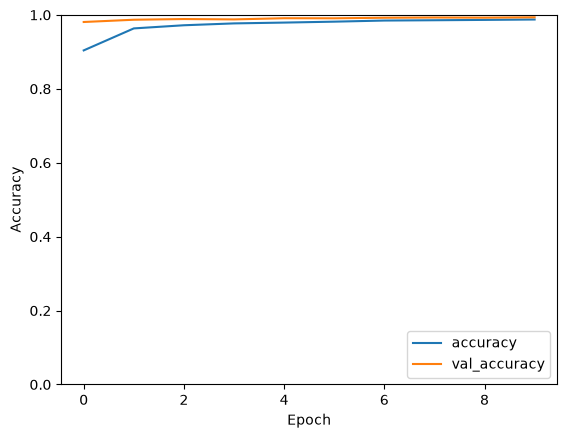

313/313 - 0s - 1ms/step - accuracy: 0.9935 - loss: 0.0281
Test accuracy: 0.9934999942779541


In [17]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')
plt.show()

test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print('Test accuracy:', test_acc)

### Part 2 / Step 9 - Sample Predictions

A quick sanity check: take `argmax` of the logits for a few test images and
compare them with the true labels.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step


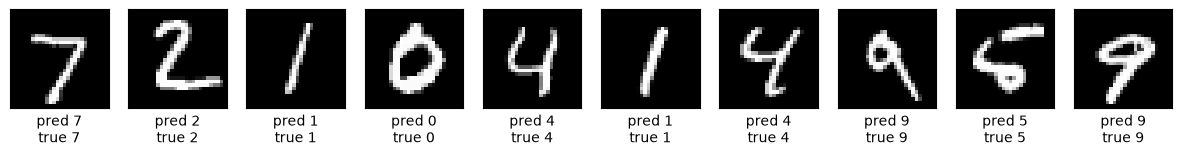

In [18]:
predictions = model.predict(test_images[:10])
predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(15, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(test_images[i].reshape(28, 28), cmap='gray')
    plt.xlabel(f'pred {predicted_labels[i]}\ntrue {test_labels[i]}')
plt.show()